# Tarea 22: Práctica SVM

### Carga de librearias y datos

In [1]:
# Load libraries for this notebook

import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [6]:
# Load the data
data_frame_original = pd.read_csv('recursos_humanos.csv')
data_frame_original.sample(5)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
14952,0.44,0.52,2,149,3,0,1,0,marketing,low
9937,0.91,0.98,5,135,3,0,0,0,sales,low
13006,0.56,0.74,3,154,2,0,0,0,hr,medium
2119,0.5,0.95,5,207,3,0,0,0,technical,low
13494,0.66,0.85,3,178,8,1,0,0,marketing,medium


Verificación de nulos y los tipos de datos en el data set

In [7]:
data_frame_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   satisfaction_level     29999 non-null  str  
 1   last_evaluation        29999 non-null  str  
 2   number_project         29999 non-null  str  
 3   average_montly_hours   29999 non-null  str  
 4   time_spend_company     29999 non-null  str  
 5   Work_accident          29999 non-null  str  
 6   left                   29999 non-null  str  
 7   promotion_last_5years  29999 non-null  str  
 8   sales                  29999 non-null  str  
 9   salary                 29999 non-null  str  
dtypes: str(10)
memory usage: 2.3 MB


### Convertir los datos a tipo numerico

Conversion de los datos de tipo cadena a tipo numerico

In [14]:
data_frame = data_frame_original.copy()

# Function to convert str values to numeric values
def convert_to_numeric(df, column_name, type):
    """ Function to convert usually str values to numeric values

    Args:
        df (DataFrame): DataFrame to be processed
        column_name (str): Name of the column to be converted
        type (str): Type to convert the column to (e.g., 'int', 'float')
    Returns:
        DataFrame: DataFrame with the specified column converted to numeric values
    """
    
    df = df[pd.to_numeric(df[column_name], errors='coerce').notnull()]
    df[column_name] = df[column_name].astype(type)
    return df

# Apply the function to convert the columns 'satisfaction_level', 'last_evaluation', 'number_project', 'time_spend_company', 'Work_accident', 'promotion_last_5years',
# and 'average_montly_hours', 'left',  to numeric values

data_frame = convert_to_numeric(data_frame, 'satisfaction_level', 'float')
data_frame = convert_to_numeric(data_frame, 'last_evaluation', 'float')
data_frame = convert_to_numeric(data_frame, 'number_project', 'int')
data_frame = convert_to_numeric(data_frame, 'time_spend_company', 'int')
data_frame = convert_to_numeric(data_frame, 'Work_accident', 'int')
data_frame = convert_to_numeric(data_frame, 'promotion_last_5years', 'int')
data_frame = convert_to_numeric(data_frame, 'average_montly_hours', 'float')
data_frame = convert_to_numeric(data_frame, 'left', 'int')

data_frame.info()
data_frame.sample(5)


<class 'pandas.DataFrame'>
Index: 29998 entries, 0 to 29998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     29998 non-null  float64
 1   last_evaluation        29998 non-null  float64
 2   number_project         29998 non-null  int64  
 3   average_montly_hours   29998 non-null  float64
 4   time_spend_company     29998 non-null  int64  
 5   Work_accident          29998 non-null  int64  
 6   left                   29998 non-null  int64  
 7   promotion_last_5years  29998 non-null  int64  
 8   sales                  29998 non-null  str    
 9   salary                 29998 non-null  str    
dtypes: float64(3), int64(5), str(2)
memory usage: 2.5 MB


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
22949,0.76,0.99,3,166.0,3,0,0,0,sales,medium
5145,0.63,0.92,2,198.0,2,0,0,0,hr,low
5771,0.53,0.60,5,247.0,3,0,0,0,technical,low
11888,0.70,0.54,3,194.0,2,1,0,0,IT,low
24857,0.54,0.87,4,163.0,3,0,0,0,sales,medium


### Codificación de variables categóricas

Las variables categoricas encontradas en los datos son: 'sales' y 'salary', se va a usar la función get_dummies de pandas para remplazarlarlas por valores numéricos.

In [15]:
data_frame_updated = pd.get_dummies(data_frame, columns=['sales', 'salary'], dtype= float)
data_frame_updated.sample(5)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
21521,0.72,0.83,3,132.0,2,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
18187,0.56,0.90,4,115.0,3,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
5634,0.23,0.49,5,214.0,5,0,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
239,0.10,0.97,7,254.0,4,0,1,0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
21436,0.29,0.86,3,251.0,4,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Modelo predictivo con el método de SVM

#### Definición de las variables para aplicar el modelo

In [17]:
X_non_normalized = data_frame_updated.drop('left', axis= 1)

Y = data_frame_updated['left']   
X_non_normalized.info()

<class 'pandas.DataFrame'>
Index: 29998 entries, 0 to 29998
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     29998 non-null  float64
 1   last_evaluation        29998 non-null  float64
 2   number_project         29998 non-null  int64  
 3   average_montly_hours   29998 non-null  float64
 4   time_spend_company     29998 non-null  int64  
 5   Work_accident          29998 non-null  int64  
 6   promotion_last_5years  29998 non-null  int64  
 7   sales_IT               29998 non-null  float64
 8   sales_RandD            29998 non-null  float64
 9   sales_accounting       29998 non-null  float64
 10  sales_hr               29998 non-null  float64
 11  sales_management       29998 non-null  float64
 12  sales_marketing        29998 non-null  float64
 13  sales_product_mng      29998 non-null  float64
 14  sales_sales            29998 non-null  float64
 15  sales_support     

In [20]:
# Data normalization
X = (X_non_normalized - np.min(X_non_normalized)) / (np.max(X_non_normalized) - np.min(X_non_normalized))
X = np.asanyarray(X)
X[0:5]

array([[1.22580645e-03, 1.70967742e-03, 6.45161290e-03, 5.06451613e-01,
        9.67741935e-03, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 3.22580645e-03, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 3.22580645e-03, 0.00000000e+00],
       [2.58064516e-03, 2.77419355e-03, 1.61290323e-02, 8.45161290e-01,
        1.93548387e-02, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 3.22580645e-03, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 3.22580645e-03],
       [3.54838710e-04, 2.83870968e-03, 2.25806452e-02, 8.77419355e-01,
        1.29032258e-02, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 3.22580645e-03, 0.0000

In [21]:
Y = np.asanyarray(Y)
Y[0:5]

array([1, 1, 1, 1, 1])

### Creacion de los datos de prueba y entrenamiento 

In [22]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size= 0.2, random_state= 4)
print('Train set:', X_train.shape, Y_train.shape)
print('Test set:', X_test.shape, Y_test.shape)

Train set: (23998, 20) (23998,)
Test set: (6000, 20) (6000,)


### Modeloado SVM 

En esta seccion se modela con diferentes kernels para identificar cual es el mas optimo

In [37]:
# function to plot a confusion matrix
import seaborn as sns
def plot_confusion_matrix(cm, tilte):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.figure(figsize=(5, 5))
    sns.heatmap(cm, annot=True, fmt=".0f", linewidths=.5, linecolor='white', square=True, cmap='Blues_r');
    plt.ylabel('Actual label')
    plt.xlabel('Predicted label')
    plt.title(tilte)
    plt.show()

Kernel: linear


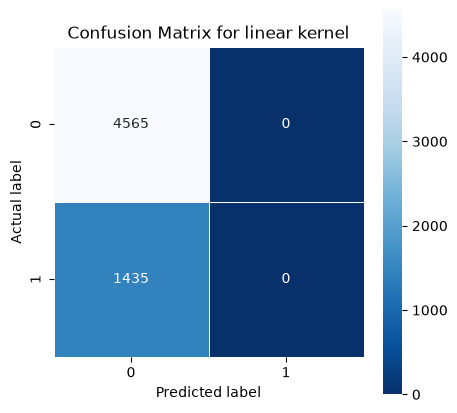

              precision    recall  f1-score   support

           0       0.76      1.00      0.86      4565
           1       0.00      0.00      0.00      1435

    accuracy                           0.76      6000
   macro avg       0.38      0.50      0.43      6000
weighted avg       0.58      0.76      0.66      6000

Kernel: poly


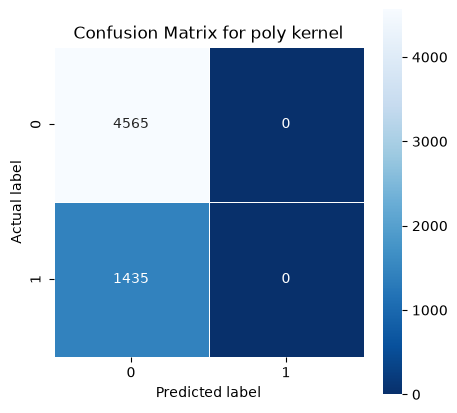

              precision    recall  f1-score   support

           0       0.76      1.00      0.86      4565
           1       0.00      0.00      0.00      1435

    accuracy                           0.76      6000
   macro avg       0.38      0.50      0.43      6000
weighted avg       0.58      0.76      0.66      6000

Kernel: rbf


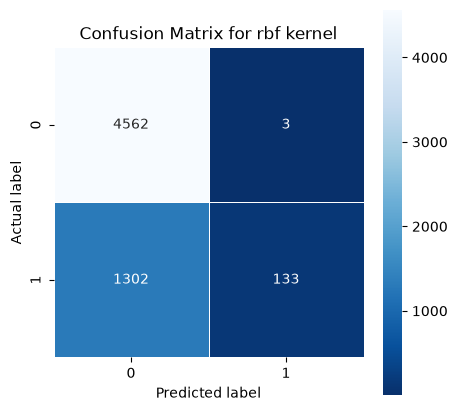

              precision    recall  f1-score   support

           0       0.78      1.00      0.87      4565
           1       0.98      0.09      0.17      1435

    accuracy                           0.78      6000
   macro avg       0.88      0.55      0.52      6000
weighted avg       0.83      0.78      0.71      6000

Kernel: sigmoid


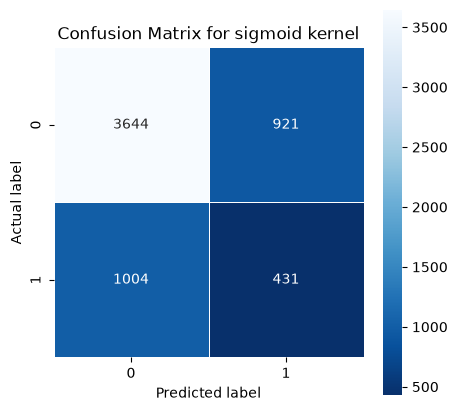

              precision    recall  f1-score   support

           0       0.78      0.80      0.79      4565
           1       0.32      0.30      0.31      1435

    accuracy                           0.68      6000
   macro avg       0.55      0.55      0.55      6000
weighted avg       0.67      0.68      0.68      6000



In [38]:
# get the optimal model for the svm method
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn import svm

def get_svm(kernel):
    ''' Function to estimate the value of the score for svm values

    Args: 
        kernel: the kernel type for the svm
    
    Returns:
        A tuple of the kernel and the score
    '''
    clf = svm.SVC(kernel=kernel)

    clf.fit(X_train, Y_train)
    y_hat = clf.predict(X_test)

    cm = confusion_matrix(Y_test, y_hat)
    report = classification_report(Y_test, y_hat)

    print(f"Kernel: {kernel}")
    plot_confusion_matrix(cm, f"Confusion Matrix for {kernel} kernel")
    print(report)

get_svm('linear')
get_svm('poly')
get_svm('rbf')
get_svm('sigmoid')

## Prediccion de un resultado

El kernel que tiene mas accuracy es el RBF, se va a usar para estimar una prediccion de un valor dado

In [46]:
  # Build the model using the rbf kernel
clf = svm.SVC(kernel='rbf')

# Train the model using the training sets
clf.fit(X_train, Y_train)

X_new = np.array([0.5, 0.75,4, 200, 4, 0,0, 0, 0, 0,0,0,0,0,1,0,0, 0,0,1])
X_new = (X_new - np.min(X_non_normalized)) / (np.max(X_non_normalized) - np.min(X_non_normalized))
X_new = np.asanyarray(X_new)
print(f"X_new: {X_new}")

y_pred = clf.predict(X_new.reshape(1, -1))
y_pred

X_new: [0.0016129  0.00241935 0.01290323 0.64516129 0.01290323 0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.00322581 0.         0.         0.
 0.         0.00322581]


array([0])

El pronostico del modelo dice que un empleado con estos datos se va a quedar y no renunciara.

## Conclusiones 
Despues de la ejecucion del modelo SVM para los diferentes kernels, el que tiene  un accuracy en el f1-score es el kernel **rbf**.

- En la grafica de la matriz de confusion del kernel RBF, se observa que:
- Valores positivos y verdadores que el modelo acerto son: 4562
- El modelo predijo negativo pero el valor real fue positivo: 3
- El modelo predijo positivo pero el valor fue negativo: 1302 
- El modelo predijo que el negativo y fue negativo: 133